**Exercise 1**:
 
* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

In [ ]:

import numpy as np
import random
import scipy.integrate as integrate


# funcion
def f(x):
    return x**0.5

# Funcion de integracion Monte Carlo
def monte_carlo_integration(func, a, b, num_samples=1000):
    integral_sum = 0

    for i in range(num_samples):
        x = random.uniform(a, b)
        integral_sum += func(x)

    integral_approx = (b-a)*(integral_sum/num_samples)

    return integral_approx

# Limites de integracion
a = 0
b = 4

# Numero de muestras
N = 100000

# Calcular la integral
integral_MC = monte_carlo_integration(f, a, b, N)

# Resultado analitico
integral_exact = integrate.quad(f,a,b)[0]

# Error absoluto
error = abs(integral_MC - integral_exact)

print("Resultado Monte Carlo:", integral_MC)
print("Resultado analitico:", integral_exact)
print("Error absoluto:", error)


Resultado Monte Carlo: 5.327961028227425
Resultado analitico: 5.333333333333335
Error absoluto: 0.005372305105909803


In [ ]:

def f(y, x):
    return x*y**2

# Limites 
a = 0
b = 2
c = 0
d = 1

# Numero de muestras
N = 100000

# integrales y error
integral_MC = monte_carlo_integration(f, a, b, c, d, N)
integral_exact = integrate.dblquad(f, a, b, lambda x: c, lambda x: d)[0]
error = abs(integral_MC - integral_exact)

print("Resultado Monte Carlo:", integral_MC)
print("Resultado analitico:", integral_exact)
print("Error absoluto:", error)


Resultado Monte Carlo: 0.6647026666174929
Resultado analitico: 0.6666666666666667
Error absoluto: 0.001964000049173853


BIEN...

**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

In [ ]:

import matplotlib.pyplot as plt

# Constante 
C = 0.6717098224  

# Parametros de la red
n = 10
N = n*n

# Interaccion entre primeros vecinos (J/kB)
J = 1.0 

# Funcion de Metropolis
def metropolis_ising(red, T, H, J):

    # Recorrer todos los espines en orden aleatorio
    sitios = np.random.permutation(n*n)

    for sitio in sitios:

        # Coordenadas del espin seleccionado
        i = sitio // n
        j = sitio % n

        # Valor del espin
        s = red[i, j]

        # Suma de los cuatro primeros vecinos
        vecinos = (
            red[(i+1) % n, j] +
            red[(i-1) % n, j] +
            red[i, (j+1) % n] +
            red[i, (j-1) % n]
        )

        # Cambio de energia dividido por kB
        deltae = 2*s*(J*vecinos + C*H)

        # Criterio de aceptacion de Metropolis
        if deltae <= 0:
            red[i, j] = -s

        else:
            p = np.exp(-deltae/T)
            r = random.random()

            if r < p:
                red[i, j] = -s

    return red


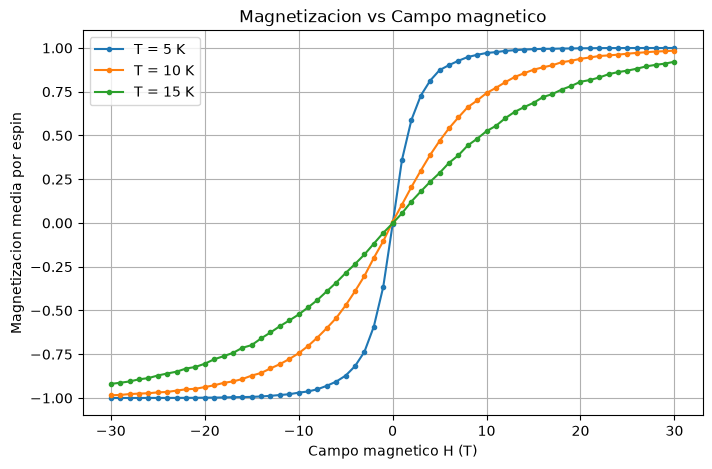

In [13]:

# Temperaturas del sistema
temperaturas = [5, 10, 15]

# Campo magnetico en Tesla
campos = np.arange(-30, 30.5, 1)

# Numero de barridos
MC = 500
equilibrio = 300

# Guardar resultados
resultados = {}

# Simulacion para cada temperatura
for T in temperaturas:

    magnetizaciones = []

    for H in campos:

        # Inicializar red con espines aleatorios
        red = np.random.choice([-1, 1], size=(n, n))

        # Guardar magnetizaciones
        Mag = []

        # Barridos de Monte Carlo
        for m in range(MC + equilibrio):

            # Aplicar algoritmo de Metropolis
            red = metropolis_ising(red, T, H, J)

            # Despues del equilibrio, medir magnetizacion
            if m >= equilibrio:
                magnetizacion = np.sum(red)/N
                Mag.append(magnetizacion)

        # Magnetizacion media
        magnetizaciones.append(np.mean(Mag))

    resultados[T] = np.array(magnetizaciones)

# Graficar resultados
plt.figure(figsize=(8, 5))

for T in temperaturas:
    plt.plot(
        campos,
        resultados[T],
        '.-',
        label=f'T = {T} K'
    )

plt.xlabel('Campo magnetico H (T)')
plt.ylabel('Magnetizacion media por espin')
plt.title('Magnetizacion vs Campo magnetico')
plt.legend()
plt.grid()
plt.show()


MUY BIEN. ENTREGA TARDE... PORQUE TOMA CONDICIONES PERIODICAS? red[(i+1) % n, j] ? NOTA 4.6